# 10 · Surrogate modelling: a neural network that replaces the power flow
**Level 4 · Simulation + ML** &nbsp;|&nbsp; Course link: *Module 4 – surrogate modelling: train a fast data-driven model on
simulation results, then use it where the physics model is too slow (planning studies, Monte Carlo, real-time control)*

An AC power flow solves non-linear equations with Newton–Raphson (notebook 02): ~20 ms per case. A planning study
over a year of 15-minute steps, many grid variants and many scenarios needs millions of power flows. A **surrogate**
learns the mapping *injections → voltages, loadings* once, then answers in microseconds.

$$\underbrace{(P_{load}, Q_{load}, P_{PV})}_{\text{inputs}} \;\xrightarrow{\ \text{AC power flow}\ }\; \underbrace{(|V|_{bus}, \text{loading}_{line})}_{\text{outputs}}
\qquad\approx\qquad f_\theta(\cdot)\ \text{(neural network)}$$

**Grid:** the stressed rural LV grid of the capstone (notebook 08): SimBench 2034 scenario with an 11 kW EV charger in
every home, so the surrogate must reproduce real overloads and low voltages.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from energy_ai import snapshots, simbench_grid, fast_pf, get_device, set_seed, style
style(); set_seed(0)
device = get_device()

CODE, EV = "1-LV-rural2--2-sw", dict(ev_share=1.0)

def xy(d):
    X = pd.concat([(d["p_load"] + d["p_ev"]).add_prefix("P_"), d["q_load"].add_prefix("Q_"), d["p_pv"].add_prefix("PV_")], axis=1) * 1000  # kW / kvar
    Y = pd.concat([d["vm"], d["line_loading"]], axis=1)
    return X, Y

d = snapshots(CODE, n=8000, seed=0, **EV)
X, Y = xy(d)
vcols, lcols = list(d["vm"].columns), list(d["line_loading"].columns)
X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.2, random_state=0)
print(f"{len(X)} power-flow results | {X.shape[1]} inputs | {len(vcols)} bus voltages + {len(lcols)} line loadings = {Y.shape[1]} outputs")

Using device: xpu (Intel(R) UHD Graphics)


8000 power-flow results | 247 inputs | 97 bus voltages + 95 line loadings = 192 outputs


## 1. Baseline: a linear surrogate (≈ linearised power flow)
Around an operating point, voltages change almost linearly with injections (that is what the Jacobian says). Line
**loading**, however, is a *current magnitude*: it rises whether power flows forward (demand) or backward (PV export),
a V-shape that no linear model can fit.

In [2]:
def scores(Y_true, Y_pred, name):
    err = np.abs(np.asarray(Y_true) - np.asarray(Y_pred))
    nv = len(vcols)
    return {"model": name, "voltage MAE [V on 400 V]": 400 * err[:, :nv].mean(), "voltage max error [V]": 400 * err[:, :nv].max(),
            "loading MAE [%-pt]": err[:, nv:].mean(), "loading max error [%-pt]": err[:, nv:].max()}

lin = Ridge(alpha=1e-3).fit(X_tr, Y_tr)
rows = [scores(Y_te, lin.predict(X_te), "linear (ridge)")]
display(pd.DataFrame(rows).set_index("model").round(2))

,voltage MAE [V on 400 V],voltage max error [V],loading MAE [%-pt],loading max error [%-pt]
model,,,,
linear (ridge),0.2,2.33,0.62,31.75


## 2. Neural-network surrogate on the GPU
A multi-output MLP: all injections → 3 hidden layers → all outputs at once. Inputs and outputs are standardised; the
outputs that never change (the slack bus) get unit scale to avoid dividing by zero.

In [3]:
class Surrogate:
    def __init__(self, hidden=256, depth=3, steps=6000, lr=2e-3, batch=256):
        self.hidden, self.depth, self.steps, self.lr, self.batch = hidden, depth, steps, lr, batch
    def fit(self, X, Y, verbose=False):
        self.xs = StandardScaler().fit(X)
        self.ym, self.ysd = Y.values.mean(0), np.where(Y.values.std(0) > 1e-9, Y.values.std(0), 1.0)
        Xt = torch.tensor(self.xs.transform(X), dtype=torch.float32, device=device)
        Yt = torch.tensor((Y.values - self.ym) / self.ysd, dtype=torch.float32, device=device)
        layers, din = [], X.shape[1]
        for _ in range(self.depth):
            layers += [nn.Linear(din, self.hidden), nn.SiLU()]; din = self.hidden
        self.net = nn.Sequential(*layers, nn.Linear(din, Y.shape[1])).to(device)
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=self.lr, total_steps=self.steps)
        self.history, step, t0 = [], 0, time.perf_counter()
        while step < self.steps:
            for b in torch.randperm(len(Xt)).to(device).split(self.batch):
                loss = nn.functional.mse_loss(self.net(Xt[b]), Yt[b])
                opt.zero_grad(); loss.backward(); opt.step(); sched.step(); step += 1
                if step % 200 == 0: self.history.append(loss.item())
                if step >= self.steps: break
        self.train_time = time.perf_counter() - t0
        return self
    def predict(self, X):
        self.net.eval()
        with torch.no_grad():
            out = self.net(torch.tensor(self.xs.transform(X), dtype=torch.float32, device=device)).cpu().numpy()
        return out * self.ysd + self.ym

nn_sur = Surrogate().fit(X_tr, Y_tr)
Y_nn = nn_sur.predict(X_te)
rows.append(scores(Y_te, Y_nn, "neural network (GPU)"))
print(f"training time: {nn_sur.train_time:.0f} s")
display(pd.DataFrame(rows).set_index("model").round(2))

training time: 40 s


,voltage MAE [V on 400 V],voltage max error [V],loading MAE [%-pt],loading max error [%-pt]
model,,,,
linear (ridge),0.20,2.33,0.62,31.75
neural network (GPU),0.06,6.97,0.35,9.96


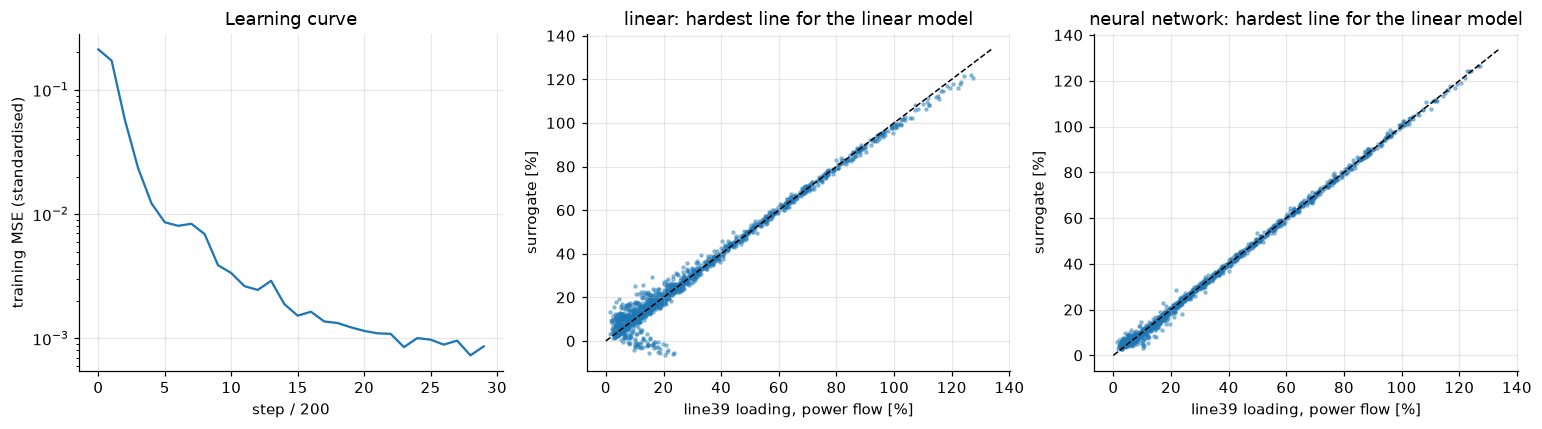

In [4]:
worst_line = (np.abs(Y_te[lcols].values - lin.predict(X_te)[:, len(vcols):])).mean(0).argmax()
lname = lcols[worst_line]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(nn_sur.history); ax[0].set(yscale="log", xlabel="step / 200", ylabel="training MSE (standardised)", title="Learning curve")
for a, pred, title in ((ax[1], lin.predict(X_te), "linear"), (ax[2], Y_nn, "neural network")):
    a.scatter(Y_te[lname], pred[:, len(vcols) + worst_line], s=4, alpha=0.4)
    lim = [0, Y_te[lname].max() * 1.05]; a.plot(lim, lim, "k--", lw=1)
    a.set(xlabel=f"{lname} loading, power flow [%]", ylabel="surrogate [%]", title=f"{title}: hardest line for the linear model")
plt.tight_layout(); plt.show()

## 3. Speed: power flow vs surrogate

In [5]:
net, prof = simbench_grid(CODE)
net.storage["in_service"] = False                       # same settings as the data generator
sample = X_te.iloc[:50]
Ps, Qs, PVs = (sample[[c for c in X.columns if c.startswith(p)]].values / 1000 for p in ("P_", "Q_", "PV_"))
fast_pf(net)                                            # warm-up: the first call builds internal structures
t0 = time.perf_counter()
for i in range(len(sample)):
    net.load["p_mw"], net.load["q_mvar"], net.sgen["p_mw"] = Ps[i], Qs[i], PVs[i]
    fast_pf(net)
t_pf = (time.perf_counter() - t0) / len(sample)

d_year = snapshots(CODE, n=None, **EV)
X_year, Y_year = xy(d_year)
nn_sur.predict(X_year.iloc[:100])                       # warm-up (GPU kernels compile on first use)
t0 = time.perf_counter(); Y_year_nn = nn_sur.predict(X_year); t_nn = (time.perf_counter() - t0) / len(X_year)
print(f"AC power flow : {1000 * t_pf:.1f} ms per case  → whole year ({len(X_year)} steps) ≈ {t_pf * len(X_year) / 60:.1f} min")
print(f"NN surrogate  : {1e6 * t_nn:.2f} µs per case → whole year in {t_nn * len(X_year):.2f} s  (×{t_pf / t_nn:,.0f} faster)")

AC power flow : 25.4 ms per case  → whole year (35136 steps) ≈ 14.8 min
NN surrogate  : 8.33 µs per case → whole year in 0.29 s  (×3,043 faster)


## 4. Using the surrogate: a full-year planning study
Question from the planner: *how many hours per year is each cable overloaded, and how low does the voltage get?*
The surrogate answers for all 35 136 quarter-hours at once; we check against the exact power flow. (The EV charging
states of the full-year run are drawn independently of the training set, so these are new cases.)

,overload hours / year (power flow),overload hours / year (surrogate)
line6,94.0,96.0
line10,6.0,6.0
line15,276.0,275.0
line19,38.0,38.0
line28,134.0,132.0
line30,157.0,158.0
line32,21.0,20.0
line34,192.0,190.0
line39,259.0,258.0
line45,1.0,0.0


lowest voltage of the year: power flow 0.8668 pu | surrogate 0.8692 pu
hours/year with any customer below 0.95 pu: power flow 680 h | surrogate 685 h


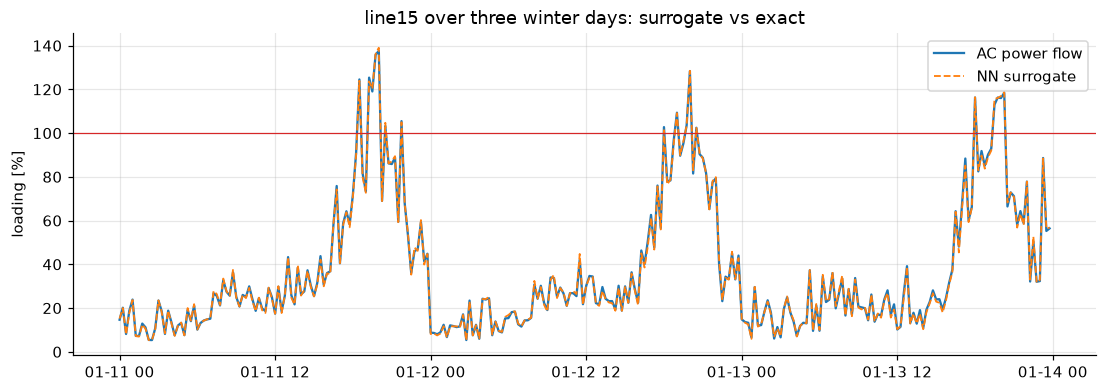

In [6]:
Yy = pd.DataFrame(Y_year_nn, index=Y_year.index, columns=Y_year.columns)
hours_exact = (Y_year[lcols] > 100).sum() * 0.25
hours_sur = (Yy[lcols] > 100).sum() * 0.25
cmp = pd.DataFrame({"overload hours / year (power flow)": hours_exact, "overload hours / year (surrogate)": hours_sur})
cmp = cmp[(cmp > 0).any(axis=1)]
display(cmp.round(0))
print(f"lowest voltage of the year: power flow {Y_year[vcols].min().min():.4f} pu | surrogate {Yy[vcols].min().min():.4f} pu")
print(f"hours/year with any customer below 0.95 pu: power flow {(Y_year[vcols].min(1) < 0.95).sum() * 0.25:.0f} h | "
      f"surrogate {(Yy[vcols].min(1) < 0.95).sum() * 0.25:.0f} h")

wk = slice("2016-01-11", "2016-01-13")
top_line = hours_exact.idxmax()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(Y_year.loc[wk, top_line], label="AC power flow", lw=1.5)
ax.plot(Yy.loc[wk, top_line], "--", label="NN surrogate", lw=1.2)
ax.axhline(100, color="tab:red", lw=0.8)
ax.set(ylabel="loading [%]", title=f"{top_line} over three winter days: surrogate vs exact"); ax.legend(); plt.show()

## 5. Limits: how much data, and what happens outside the training range?
### 5a. Sample efficiency

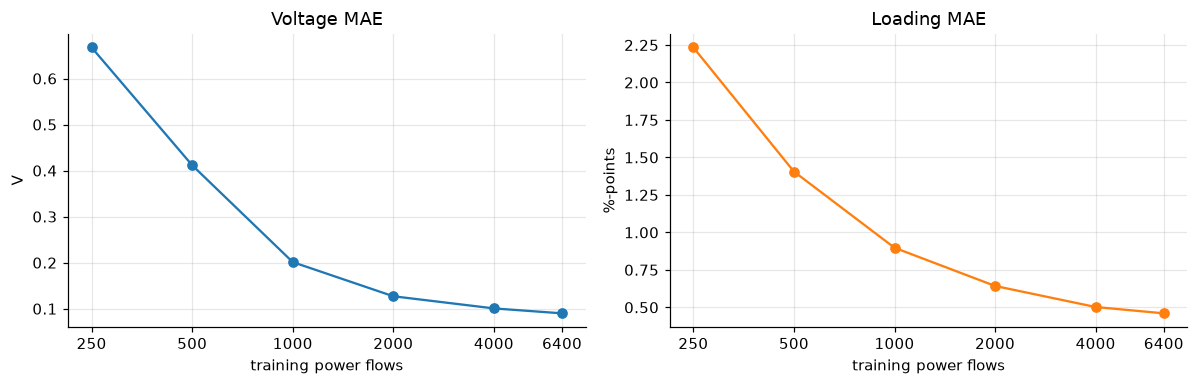

In [7]:
curve = []
for n in (250, 500, 1000, 2000, 4000, len(X_tr)):
    s = Surrogate(steps=3000).fit(X_tr.iloc[:n], Y_tr.iloc[:n])
    r = scores(Y_te, s.predict(X_te), n); r["train samples"] = n; curve.append(r)
curve = pd.DataFrame(curve).set_index("train samples").drop(columns="model")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(curve.index, curve["voltage MAE [V on 400 V]"], "o-"); ax[0].set(xscale="log", xlabel="training power flows", ylabel="V", title="Voltage MAE")
ax[1].plot(curve.index, curve["loading MAE [%-pt]"], "o-", color="tab:orange"); ax[1].set(xscale="log", xlabel="training power flows", ylabel="%-points", title="Loading MAE")
for a in ax:
    a.minorticks_off(); a.set_xticks(curve.index); a.set_xticklabels(curve.index)
plt.tight_layout(); plt.show()

### 5b. New scenarios: how far can the surrogate be trusted?
Two what-if scenarios, 1 000 new power flows each, never seen in training:
* **household and business demand ×1.3** (EVs unchanged): more of the same kind of loading;
* **PV capacity ×4**: at sunny noon the feeders export power and voltages *rise*, a regime that barely exists in the
  training data.

In [8]:
X_hi, Y_hi = xy(snapshots(CODE, n=1000, seed=2, load_scale=1.3, **EV))
X_pv, Y_pv = xy(snapshots(CODE, n=1000, seed=3, pv_scale=4.0, **EV))
out_rows = [dict(scores(Y_te, Y_nn, "NN · test set (same distribution)")),
            dict(scores(Y_hi, nn_sur.predict(X_hi), "NN · demand ×1.3")),
            dict(scores(Y_hi, lin.predict(X_hi), "linear · demand ×1.3")),
            dict(scores(Y_pv, nn_sur.predict(X_pv), "NN · PV ×4")),
            dict(scores(Y_pv, lin.predict(X_pv), "linear · PV ×4"))]
display(pd.DataFrame(out_rows).set_index("model").round(2))
print(f"highest voltage: training data {Y[vcols].max().max():.3f} pu | PV ×4 scenario {Y_pv[vcols].max().max():.3f} pu")
print(f"PV feed-in seen in training up to {X_tr.filter(like='PV_').sum(1).max():.0f} kW | PV ×4 scenario up to {X_pv.filter(like='PV_').sum(1).max():.0f} kW")

,voltage MAE [V on 400 V],voltage max error [V],loading MAE [%-pt],loading max error [%-pt]
model,,,,
NN · test set (same distribution),0.06,6.97,0.35,9.96
NN · demand ×1.3,0.06,7.62,0.35,7.24
linear · demand ×1.3,0.19,3.42,0.58,24.26
NN · PV ×4,0.22,53.92,1.42,58.05
linear · PV ×4,0.32,2.95,2.86,174.34


highest voltage: training data 1.036 pu | PV ×4 scenario 1.075 pu
PV feed-in seen in training up to 135 kW | PV ×4 scenario up to 509 kW


**Reading the table.** More demand of the same kind is no problem: the EV-heavy training data already spans those
loading levels. Quadrupled PV is a **regime change** (power flows backwards, voltages rise above anything seen):
the network's *average* error grows about 4× and its *worst* errors explode to tens of volts and tens of %-points,
i.e. completely wrong answers exactly in the situations a planner cares about. The linear model extrapolates the
voltages gracefully (they are nearly linear in the injections) but still fails on loadings.

## Key takeaways
* A surrogate is trained **once** on simulator output and then evaluates a full year of quarter-hours in well under a
  second; the planning statistics (overload hours, voltage-violation hours) match the exact power flow closely.
* Linear surrogates (≈ linearised power flow) handle voltages but fail on current magnitudes when power can flow in both
  directions; neural networks capture that non-linearity. Check the **worst case**, not only the average: the network
  has the lower mean error but occasionally larger single errors.
* Accuracy grows with the number of training simulations; the cost of generating them is paid offline.
* Surrogates are trustworthy only **inside the training distribution**. For a new regime, generate new simulations
  (or put physics into the model, notebook 13) and always keep the exact solver for verification.